In [ ]:
import pandas as pd, numpy as np
from google.colab import drive
drive.mount('/content/drive')

P = '/content/drive/MyDrive/Component1/catalogues'

lin_flares = pd.read_csv(f'{P}/lin2024_flares.csv')
lin_stars  = pd.read_csv(f'{P}/lin2024_stars.csv')
g_flares   = pd.read_csv(f'{P}/gunther2020_flares.csv')
g_stars    = pd.read_csv(f'{P}/gunther2020_stars.csv')

for name, df in [('Lin flares', lin_flares), ('Lin stars', lin_stars),
                 ('Günther flares', g_flares), ('Günther stars', g_stars)]:
    print(f'\n{name}: {len(df):,} rows')
    print(df.columns.tolist())

Mounted at /content/drive

Lin flares: 249,562 rows
['recno', 'TIC', 'FAmp', 'FAmp-cal', 'FDur', 'FDur-cal', 'FEner', 'FEner-cal', 'ED1/ED2', 't1/t2', 'tStart', 'tPeak', 'tEnd']

Lin stars: 18,032 rows
['recno', 'TIC', 'RAJ2000', 'DEJ2000', 'BP-RP', 'Gmag', 'Tmag', 'Teff', 'Rad', 'Dist', 'Prot', 'e_Prot', 'Vamp', 'e_Vamp', 'Rcont', 'Nf', 'Simbad']

Günther flares: 8,695 rows
['recno', 'TIC', 'Sec', 'Outbst', 'Flare', 'tpeak', 'e_tpeak', 'E_tpeak', 'Amp', 'e_Amp', 'E_Amp', 'FWHMdt', 'e_FWHMdt', 'E_FWHMdt', 'Ebol', 'e_Ebol', 'E_Ebol', 'MCME', 'e_MCME', 'E_MCME', 'Tmag', 'Teff', 'Rad', 'logg', 'SpT', 'Prot-t', 'Prot-k', 'Prot', 'aFFD', 'bFFD', 'Chem', 'O3cons', 'O3perm', 'Dup']

Günther stars: 1,228 rows
['recno', 'TIC', 'Sec', 'Nout', 'Nfl', 'Amp_max', 'Amp_mean', 'FWHMdt_max', 'FWHMdt_mean', 'Ebol_max', 'Ebol_mean', 'MCME_max', 'MCME_mean', 'Tmag', 'Teff', 'Rad', 'logg', 'SpT', 'Prot-t', 'Prot-k', 'Prot', 'aFFD', 'bFFD', 'Chem', 'O3cons', 'O3perm', 'Dup', 'SimbadName', '_RA', '_DE']


In [ ]:
g = g_flares.copy()
g['tpeak_btjd'] = g['tpeak'] - 2457000              # Günther time → BTJD

both = g.merge(lin_flares[['TIC', 'tPeak', 'FEner', 'FEner-cal']], on='TIC')
both = both[(both['tpeak_btjd'] - both['tPeak']).abs() < 10/1440]   # same flare: within 10 min

for col in ['FEner', 'FEner-cal']:
    diff = np.log10(both['Ebol']) - np.log10(both[col])
    print(f'{col}: {len(both)} shared flares | offset (median) {diff.median():.2f} | spread {diff.std():.2f}')

FEner: 6394 shared flares | offset (median) 0.36 | spread 0.36
FEner-cal: 6394 shared flares | offset (median) 0.36 | spread 0.36


In [ ]:
same = np.isclose(lin_flares['FEner'], lin_flares['FEner-cal'])
print(f"FEner equals FEner-cal for {same.mean():.1%} of Lin flares")
print(lin_flares[['FEner', 'FEner-cal']].head())

FEner equals FEner-cal for 14.6% of Lin flares
          FEner     FEner-cal
0  2.870000e+32  2.890000e+32
1  1.150000e+32  1.160000e+32
2  8.530000e+32  8.570000e+32
3  2.260000e+32  2.280000e+32
4  1.320000e+33  1.330000e+33


In [ ]:
r = np.log10(lin_flares['FEner-cal'] / lin_flares['FEner'])
print(r.describe().round(4))
print('flares where they differ by more than 0.1 dex (~26%):', (r.abs() > 0.1).sum())

count    244417.0000
mean          0.0025
std           0.0034
min          -0.0503
25%           0.0012
50%           0.0020
75%           0.0030
max           0.0889
dtype: float64
flares where they differ by more than 0.1 dex (~26%): 0


1. Lin stars per type:
 type
M          9617
K          3370
G          2144
F          1501
unknown    1235
hotter      165
Name: count, dtype: int64 

2. Lin flares per type:
 type
M          144938
K           43688
G           25188
unknown     21358
F           13090
hotter       1300
Name: count, dtype: int64 

3. Günther stars per type:
 type
M          674
K          178
unknown    155
G          120
F           85
hotter      16
Name: count, dtype: int64 

4. Lin tPeak range (BTJD): 1325.3 - 3285.6
   Günther tpeak range (BJD): 2458325.3 - 2458381.5 

5. Lin (bolometric): missing 5,145 | log10 min 29.69, median 33.08, max 39.58
5. Günther: missing 1,427 | log10 min 30.98, median 33.10, max 36.92

6. Lin flares per energy type:
 FEner
Solar-like            17611
Large                 94157
Superflare            95528
Extreme superflare    37121
Name: count, dtype: int64

   Günther flares per energy type:
 Ebol
Solar-like             295
Large                 2938
Superflare   

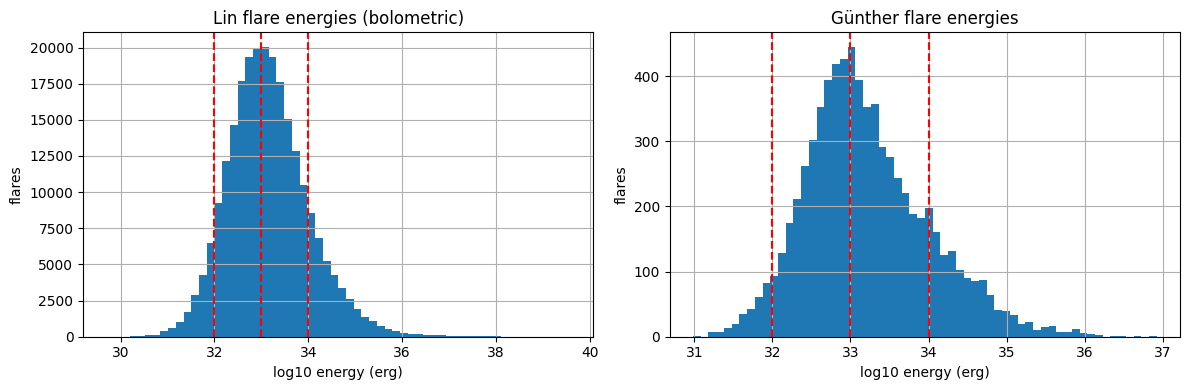

In [ ]:
import matplotlib.pyplot as plt

# ---- star type from temperature ----
def star_type(t):
    if pd.isna(t):  return 'unknown'
    if t >= 7500:   return 'hotter'
    if t >= 6000:   return 'F'
    if t >= 5300:   return 'G'
    if t >= 3900:   return 'K'
    return 'M'

lin_stars['type'] = lin_stars['Teff'].apply(star_type)
g_stars['type']   = g_stars['Teff'].apply(star_type)
g_flares['type']  = g_flares['Teff'].apply(star_type)

# Lin flares + their star's values (joined by TIC)
lf = lin_flares.merge(lin_stars[['TIC', 'type', 'Teff', 'Rad', 'Rcont']], on='TIC', how='left')

# ---- 1-3. How many stars and flares per type (is the data imbalanced?) ----
print('1. Lin stars per type:\n', lin_stars['type'].value_counts(), '\n')
print('2. Lin flares per type:\n', lf['type'].value_counts(), '\n')
print('3. Günther stars per type:\n', g_stars['type'].value_counts(), '\n')

# ---- 4. Time format check ----
print('4. Lin tPeak range (BTJD):', round(lin_flares['tPeak'].min(), 1), '-', round(lin_flares['tPeak'].max(), 1))
print('   Günther tpeak range (BJD):', round(g_flares['tpeak'].min(), 1), '-', round(g_flares['tpeak'].max(), 1), '\n')

# ---- 5. Energy: range and missing values (Lin converted to bolometric with +0.36 dex) ----
lin_logE = np.log10(lf['FEner'].where(lf['FEner'] > 0)) + 0.36
g_logE   = np.log10(g_flares['Ebol'].where(g_flares['Ebol'] > 0))
for name, e in [('Lin (bolometric)', lin_logE), ('Günther', g_logE)]:
    print(f'5. {name}: missing {e.isna().sum():,} | log10 min {e.min():.2f}, median {e.median():.2f}, max {e.max():.2f}')

# ---- 6. How many flares fall in each energy type ----
bins   = [-np.inf, 32, 33, 34, np.inf]
labels = ['Solar-like', 'Large', 'Superflare', 'Extreme superflare']
print('\n6. Lin flares per energy type:\n', pd.cut(lin_logE, bins, labels=labels).value_counts().sort_index())
print('\n   Günther flares per energy type:\n', pd.cut(g_logE, bins, labels=labels).value_counts().sort_index())

# ---- 7. Star value ranges (spot giants, odd values, missing values) ----
print('\n7. Lin stars:\n', lin_stars[['Teff', 'Rad', 'Rcont']].describe().round(3))
print('\n   Günther stars:\n', g_stars[['Teff', 'Rad', 'logg', 'Dup']].describe().round(3))

# ---- 8. Günther stars that are also in Lin (must be removed from training) ----
print('\n8. Günther stars also in Lin:', g_stars['TIC'].isin(lin_stars['TIC']).sum(), 'of', len(g_stars))

# ---- 9. Energy histograms with your type boundaries ----
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
lin_logE.dropna().hist(bins=60, ax=ax[0]);  ax[0].set_title('Lin flare energies (bolometric)')
g_logE.dropna().hist(bins=60, ax=ax[1]);    ax[1].set_title('Günther flare energies')
for a in ax:
    a.set_xlabel('log10 energy (erg)'); a.set_ylabel('flares')
    for x in (32, 33, 34):
        a.axvline(x, color='red', ls='--')
plt.tight_layout(); plt.show()

In [ ]:
rng = np.random.default_rng(42)              # fixed seed → same selection every time
STARS_PER_TYPE = 250
TYPES = ['F', 'G', 'K', 'M']

# ---------- 1. Filter Lin stars ----------
g_tics = set(g_stars['TIC'])
lin_ok = lin_stars[
    lin_stars['type'].isin(TYPES) &          # F/G/K/M only (drops unknown + hotter)
    (lin_stars['Rad'] <= 2) &                # no giants
    (lin_stars['Rcont'] < 0.1) &             # low contamination
    ~lin_stars['TIC'].isin(g_tics)           # no Günther stars (avoid leakage)
].copy()
print('Lin stars after filters, per type:\n', lin_ok['type'].value_counts(), '\n')

# ---------- 2. Filter Günther stars ----------
g_ok = g_stars[
    g_stars['type'].isin(TYPES) &
    (g_stars['logg'] >= 4) &                 # dwarfs only
    (g_stars['Rad'] <= 2) &
    (g_stars['Dup'] == 0)                    # no duplicates
].copy()
print('Günther stars after filters, per type:\n', g_ok['type'].value_counts(), '\n')

# ---------- 3. Balance Lin: same number of stars per type ----------
picked = []
for t in TYPES:
    pool = lin_ok.loc[lin_ok['type'] == t, 'TIC'].values
    n = min(STARS_PER_TYPE, len(pool))
    picked += list(rng.choice(pool, size=n, replace=False))
lin_sel = lin_ok[lin_ok['TIC'].isin(picked)].copy()
print('Lin stars selected (balanced), per type:\n', lin_sel['type'].value_counts(), '\n')

# ---------- 4. Flares of the chosen stars + energy labels ----------
lin_fl = lin_flares[lin_flares['TIC'].isin(picked)].merge(
    lin_sel[['TIC', 'type', 'Teff', 'Rad', 'Rcont']], on='TIC')
lin_fl = lin_fl[lin_fl['tPeak'] > 1382].copy()          # sector 3 onwards only
lin_fl['logE'] = np.log10(lin_fl['FEner'].where(lin_fl['FEner'] > 0)) + 0.36   # → bolometric
lin_fl['tpeak_btjd'] = lin_fl['tPeak']

g_fl = g_flares[g_flares['TIC'].isin(g_ok['TIC'])].copy()
g_fl['type'] = g_fl['Teff'].apply(star_type)
g_fl['logE'] = np.log10(g_fl['Ebol'].where(g_fl['Ebol'] > 0))
g_fl['tpeak_btjd'] = g_fl['tpeak'] - 2457000

# ---------- 5. Check counts and energy range after filtering ----------
for name, df in [('Lin (selected)', lin_fl), ('Günther (test)', g_fl)]:
    print(f'{name}: {df["TIC"].nunique()} stars | {len(df):,} flares | '
          f'with energy {df["logE"].notna().sum():,} | '
          f'log10 E min {df["logE"].min():.2f}, median {df["logE"].median():.2f}, max {df["logE"].max():.2f}')
    print('   flares per star type:', df['type'].value_counts().to_dict())
    print('   flares per energy type:',
          pd.cut(df['logE'], [-np.inf, 32, 33, 34, np.inf],
                 labels=['Solar-like', 'Large', 'Superflare', 'Extreme']).value_counts().sort_index().to_dict(), '\n')

# ---------- 6. Save ----------
OUT = '/content/drive/MyDrive/Component1/selected'
import os; os.makedirs(OUT, exist_ok=True)
lin_sel.to_csv(f'{OUT}/lin_selected_stars.csv', index=False)
lin_fl.to_csv(f'{OUT}/lin_selected_flares.csv', index=False)
g_ok.to_csv(f'{OUT}/gunther_selected_stars.csv', index=False)
g_fl.to_csv(f'{OUT}/gunther_selected_flares.csv', index=False)
print('Saved to', OUT)

Lin stars after filters, per type:
 type
M    6025
K    1983
G    1403
F     854
Name: count, dtype: int64 

Günther stars after filters, per type:
 type
M    637
K    134
G     79
F     63
Name: count, dtype: int64 

Lin stars selected (balanced), per type:
 type
M    250
F    250
K    250
G    250
Name: count, dtype: int64 

Lin (selected): 985 stars | 10,659 flares | with energy 10,622 | log10 E min 30.57, median 33.42, max 37.22
   flares per star type: {'M': 3100, 'K': 2931, 'G': 2454, 'F': 2174}
   flares per energy type: {'Solar-like': 385, 'Large': 2443, 'Superflare': 5366, 'Extreme': 2428} 

Günther (test): 913 stars | 6,385 flares | with energy 6,385 | log10 E min 30.98, median 33.08, max 35.98
   flares per star type: {'M': 4913, 'K': 891, 'G': 424, 'F': 157}
   flares per energy type: {'Solar-like': 251, 'Large': 2636, 'Superflare': 2567, 'Extreme': 931} 

Saved to /content/drive/MyDrive/Component1/selected


In [ ]:
!pip install lightkurve astroquery -q
import lightkurve as lk, os, time
import numpy as np, pandas as pd

SEL = '/content/drive/MyDrive/Component1/selected'
LC  = '/content/drive/MyDrive/Component1/lightcurves'
os.makedirs(LC, exist_ok=True)

PILOT = False                 # True = 5 stars per type first; then set False for the full run
MAX_SECTORS = 2

lin_sel = pd.read_csv(f'{SEL}/lin_selected_stars.csv')
lin_fl  = pd.read_csv(f'{SEL}/lin_selected_flares.csv')
g_ok    = pd.read_csv(f'{SEL}/gunther_selected_stars.csv')
g_fl    = pd.read_csv(f'{SEL}/gunther_selected_flares.csv')

def search(tic, tries=3):
    for k in range(tries):
        try:
            return lk.search_lightcurve(f"TIC {tic}", mission="TESS", author="SPOC", exptime=120)
        except Exception:
            time.sleep(10 * (k + 1))
    return None

def save_lc(row, tic, sector, tries=3):
    path = f'{LC}/TIC{tic}_S{sector:02d}.csv'
    if os.path.exists(path):
        return 'exists'
    for k in range(tries):
        try:
            lc = row.download(quality_bitmask="default").remove_nans()
            pd.DataFrame({'time': lc.time.value,
                          'flux': lc.flux.value,          # PDCSAP flux
                          'flux_err': lc.flux_err.value}).to_csv(path, index=False)
            return 'saved'
        except Exception:
            time.sleep(10 * (k + 1))
    return 'failed'

def sector_of(r):
    return int(str(r.mission[0]).split()[-1])

log = []

# ---------- Lin stars (training pool) ----------
stars = lin_sel
if PILOT:
    stars = stars.groupby('type').head(5)
for i, tic in enumerate(stars['TIC'], 1):
    res = search(tic)
    if res is None or len(res) == 0:
        log.append((tic, None, 'no data')); continue
    peaks = lin_fl.loc[lin_fl['TIC'] == tic, 'tpeak_btjd'].values
    good = []
    for j in range(len(res)):
        s = sector_of(res[j])
        if s < 3:
            continue
        t0 = float(res.table['t_min'][j]) - 56999.5        # MJD → BTJD
        t1 = float(res.table['t_max'][j]) - 56999.5
        if ((peaks >= t0) & (peaks <= t1)).any():           # sector contains catalogue flares
            good.append((s, res[j]))
    for s, r in good[:MAX_SECTORS]:
        log.append((tic, s, save_lc(r, tic, s)))
    if i % 10 == 0:
        print(f'Lin: {i}/{len(stars)} stars done')

# ---------- Günther stars (test set) ----------
gstars = g_fl[['TIC', 'Sec']].drop_duplicates()
if PILOT:
    gstars = gstars.head(20)
for i, (tic, sec) in enumerate(gstars.itertuples(index=False), 1):
    res = search(tic)
    if res is None or len(res) == 0:
        log.append((tic, sec, 'no data')); continue
    match = [res[j] for j in range(len(res)) if sector_of(res[j]) == int(sec)]
    log.append((tic, sec, save_lc(match[0], tic, int(sec)) if match else 'sector not found'))
    if i % 10 == 0:
        print(f'Günther: {i}/{len(gstars)} done')

log = pd.DataFrame(log, columns=['TIC', 'sector', 'status'])
log.to_csv(f'{LC}/download_log_{"pilot" if PILOT else "full"}.csv', index=False)
print(log['status'].value_counts())

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.


/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


Lin: 10/1000 stars done
Lin: 20/1000 stars done
Lin: 30/1000 stars done
Lin: 40/1000 stars done


Lin: 50/1000 stars done
Lin: 60/1000 stars done


Lin: 70/1000 stars done
Lin: 80/1000 stars done


Lin: 90/1000 stars done


... (26 outputs left out)

Lin: 870/1000 stars done


Lin: 880/1000 stars done
Lin: 890/1000 stars done
Lin: 900/1000 stars done


Lin: 910/1000 stars done
Lin: 920/1000 stars done
Lin: 930/1000 stars done
Lin: 940/1000 stars done
Lin: 950/1000 stars done
Lin: 960/1000 stars done
Lin: 970/1000 stars done
Lin: 980/1000 stars done


Lin: 990/1000 stars done
Lin: 1000/1000 stars done
Günther: 10/1088 done
Günther: 20/1088 done
Günther: 30/1088 done
Günther: 40/1088 done
Günther: 50/1088 done
Günther: 60/1088 done
Günther: 70/1088 done
Günther: 80/1088 done
Günther: 90/1088 done
Günther: 100/1088 done
Günther: 110/1088 done
Günther: 120/1088 done
Günther: 130/1088 done
Günther: 140/1088 done
Günther: 150/1088 done
Günther: 160/1088 done
Günther: 170/1088 done
Günther: 180/1088 done
Günther: 190/1088 done
Günther: 200/1088 done
Günther: 210/1088 done
Günther: 220/1088 done
Günther: 230/1088 done
Günther: 240/1088 done
Günther: 250/1088 done
Günther: 260/1088 done
Günther: 270/1088 done
Günther: 280/1088 done
Günther: 290/1088 done
Günther: 300/1088 done
Günther: 310/1088 done
Günther: 320/1088 done
Günther: 330/1088 done
Günther: 340/1088 done
Günther: 350/1088 done
Günther: 360/1088 done
Günther: 370/1088 done
Günther: 380/1088 done
Günther: 390/1088 done
Günther: 400/1088 done
Günther: 410/1088 done
Günther: 420/10

Mounted at /content/drive
50 light curve files saved


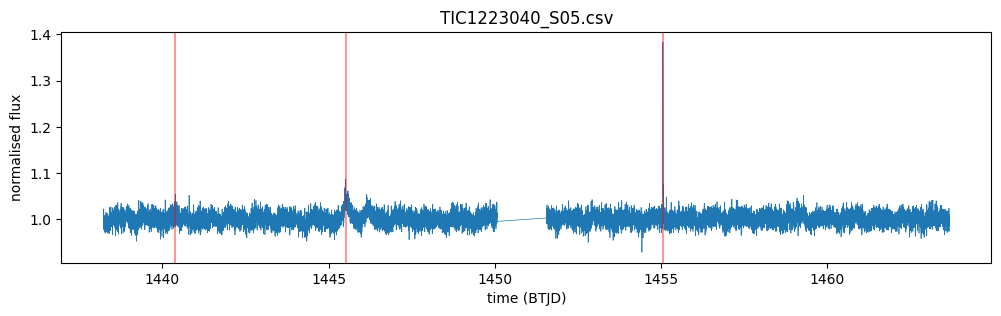

          time       flux  flux_err
0  1438.236308  424.59006  6.097737
1  1438.237697  435.47202  6.103128
2  1438.239086  416.48825  6.073128
3  1438.240475  426.64188  6.079925
4  1438.241864  426.33072  6.060487 
 17066 points


In [ ]:
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

SEL = '/content/drive/MyDrive/Component1/selected'
LC  = '/content/drive/MyDrive/Component1/lightcurves'

lin_fl = pd.read_csv(f'{SEL}/lin_selected_flares.csv')
g_fl   = pd.read_csv(f'{SEL}/gunther_selected_flares.csv')

files = sorted(f for f in os.listdir(LC) if f.startswith('TIC'))
print(len(files), 'light curve files saved')

f = files[0]                                   # change the number to look at other files
lc = pd.read_csv(f'{LC}/{f}')
tic = int(f.split('_')[0][3:])

plt.figure(figsize=(12, 3))
plt.plot(lc['time'], lc['flux'] / np.median(lc['flux']), lw=0.5)
for p in pd.concat([lin_fl, g_fl]).query('TIC == @tic')['tpeak_btjd']:
    if lc['time'].min() <= p <= lc['time'].max():
        plt.axvline(p, color='red', alpha=0.4)        # catalogue flares in this sector
plt.title(f); plt.xlabel('time (BTJD)'); plt.ylabel('normalised flux'); plt.show()
print(lc.head(), '\n', len(lc), 'points')

In [ ]:
!pip install lightkurve astroquery -q
import os, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from astroquery.mast import Catalogs

CAT = '/content/drive/MyDrive/Component1/catalogues'
SEL = '/content/drive/MyDrive/Component1/selected'
LC  = '/content/drive/MyDrive/Component1/lightcurves'
OUT = '/content/drive/MyDrive/Component1/dataset'
os.makedirs(OUT, exist_ok=True)

WINDOW, CADENCE = 128, 2 / 1440            # 128 points, 2 minutes in days
PEAK_POS = (0.2, 0.6)                      # peak placed between 20% and 60% of the window
QUIET_PER_FLARE = 2
QUIET_MARGIN = 0.05                        # quiet windows stay ≥ 0.05 d (~1.2 h) from any flare
rng = np.random.default_rng(42)

# ---- flare lists ----
lin_fl  = pd.read_csv(f'{SEL}/lin_selected_flares.csv')
g_fl    = pd.read_csv(f'{SEL}/gunther_selected_flares.csv')
lin_sel = pd.read_csv(f'{SEL}/lin_selected_stars.csv')
g_ok    = pd.read_csv(f'{SEL}/gunther_selected_stars.csv')

# ALL catalogue flare times (not just selected ones) → quiet windows avoid every known flare
all_lin = pd.read_csv(f'{CAT}/lin2024_flares.csv')[['TIC', 'tPeak']].rename(columns={'tPeak': 't'})
all_g   = pd.read_csv(f'{CAT}/gunther2020_flares.csv')[['TIC', 'tpeak']]
all_g['t'] = all_g['tpeak'] - 2457000
all_peaks = pd.concat([all_lin, all_g[['TIC', 't']]]).groupby('TIC')['t'].apply(np.array).to_dict()

# ---- star values: Teff, radius, contamination ----
star_vals = {r.TIC: (r.Teff, r.Rad, r.Rcont, r.type) for r in lin_sel.itertuples()}
print('Looking up contamination for Günther stars in the TIC...')
g_tics = g_ok['TIC'].astype(int).tolist()
contam = {}
for k in range(0, len(g_tics), 100):                   # 100 stars per query
    tab = Catalogs.query_criteria(catalog="Tic", ID=g_tics[k:k+100]).to_pandas()
    contam.update(dict(zip(tab['ID'].astype(int), tab['contratio'])))
for r in g_ok.itertuples():
    star_vals[r.TIC] = (r.Teff, r.Rad, contam.get(int(r.TIC), np.nan), r.type)

# ---- helpers ----
def cut(t, f, e, start):
    """128-point window starting at index `start`; None if out of range or crossing a gap."""
    end = start + WINDOW
    if start < 0 or end > len(t) or t[end - 1] - t[start] > (WINDOW - 1) * CADENCE * 1.1:
        return None
    return f[start:end], e[start:end]

def snr_of(fw, ew, peak):
    """Flare height above the pre-flare level ÷ flux_err at the peak."""
    pre = fw[max(peak - 15, 0):max(peak - 2, 1)]
    base = np.median(pre) if len(pre) >= 3 else np.median(fw)
    height = fw[max(peak - 2, 0):peak + 3].max() - base
    return height / ew[peak], height

# ---- build windows ----
X_flux, X_err, S, rows = [], [], [], []
flares_by = {'lin': lin_fl, 'gunther': g_fl}
files = sorted(f for f in os.listdir(LC) if f.startswith('TIC'))

for n, fname in enumerate(files, 1):
    tic, sector = int(fname[3:].split('_')[0]), int(fname.split('_S')[1][:2])
    src = 'gunther' if sector <= 2 else 'lin'
    if tic not in star_vals:
        continue
    lc = pd.read_csv(f'{LC}/{fname}')
    t, f, e = lc['time'].values, lc['flux'].values, lc['flux_err'].values
    med = np.median(f); f, e = f / med, e / med                      # normalise: normal = 1
    teff, rad, cont, stype = star_vals[tic]

    fl = flares_by[src]
    fl = fl[(fl['TIC'] == tic) & (fl['tpeak_btjd'] >= t[0]) & (fl['tpeak_btjd'] <= t[-1])]
    peaks_all = all_peaks.get(tic, np.array([]))
    n_pos = 0

    # flare windows
    for r in fl.itertuples():
        i = int(np.argmin(np.abs(t - r.tpeak_btjd)))
        if abs(t[i] - r.tpeak_btjd) > 3 * CADENCE:                  # peak not in the data
            continue
        off = int(rng.integers(int(PEAK_POS[0] * WINDOW), int(PEAK_POS[1] * WINDOW)))
        w = cut(t, f, e, i - off)
        if w is None:
            continue
        fw, ew = w[0] / np.median(w[0]), w[1] / np.median(w[0])
        snr, height = snr_of(fw, ew, off)
        X_flux.append(fw.astype(np.float32)); X_err.append(ew.astype(np.float32))
        S.append((teff, rad, cont))
        rows.append(dict(TIC=tic, sector=sector, source=src, type=stype, y_flare=1,
                         y_logE=r.logE, tpeak_btjd=r.tpeak_btjd, peak_index=off,
                         snr=snr, height=height, low_snr=bool(snr < 5)))
        n_pos += 1

    # quiet windows
    need, tries = n_pos * QUIET_PER_FLARE, 0
    while need > 0 and tries < 200 * QUIET_PER_FLARE and len(t) > WINDOW:
        tries += 1
        s = int(rng.integers(0, len(t) - WINDOW))
        w = cut(t, f, e, s)
        if w is None:
            continue
        if ((peaks_all >= t[s] - QUIET_MARGIN) & (peaks_all <= t[s + WINDOW - 1] + QUIET_MARGIN)).any():
            continue
        fw, ew = w[0] / np.median(w[0]), w[1] / np.median(w[0])
        X_flux.append(fw.astype(np.float32)); X_err.append(ew.astype(np.float32))
        S.append((teff, rad, cont))
        rows.append(dict(TIC=tic, sector=sector, source=src, type=stype, y_flare=0,
                         y_logE=np.nan, tpeak_btjd=np.nan, peak_index=-1,
                         snr=np.nan, height=np.nan, low_snr=False))
        need -= 1

    if n % 200 == 0:
        print(f'{n}/{len(files)} files | {len(rows):,} windows so far')

# ---- save ----
meta = pd.DataFrame(rows)
np.savez_compressed(f'{OUT}/flare_dataset.npz',
                    X_flux=np.stack(X_flux), X_err=np.stack(X_err),
                    star=np.array(S, dtype=np.float32),          # Teff, radius, contamination
                    y_flare=meta['y_flare'].values, y_logE=meta['y_logE'].values.astype(np.float32))
meta.to_csv(f'{OUT}/flare_dataset_meta.csv', index=False)

# ---- summary ----
print('\nTotal windows:', len(meta))
print(pd.crosstab([meta['source'], meta['type']], meta['y_flare']).rename(columns={0: 'quiet', 1: 'flare'}))
fl_rows = meta[meta['y_flare'] == 1]
print('\nFlare windows with energy:', fl_rows['y_logE'].notna().sum(), 'of', len(fl_rows))
print('Low-SNR flare windows:', fl_rows['low_snr'].sum(), f'({fl_rows["low_snr"].mean():.0%})')
print('Missing contamination:', int(np.isnan(np.array(S)[:, 2]).sum()), 'windows')

Looking up contamination for Günther stars in the TIC...
200/2631 files | 3,339 windows so far
400/2631 files | 6,225 windows so far
600/2631 files | 9,210 windows so far
800/2631 files | 12,528 windows so far
1000/2631 files | 15,693 windows so far
1200/2631 files | 18,552 windows so far
1400/2631 files | 21,717 windows so far
1600/2631 files | 24,378 windows so far
1800/2631 files | 26,865 windows so far
2000/2631 files | 29,322 windows so far
2200/2631 files | 32,106 windows so far
2400/2631 files | 34,641 windows so far
2600/2631 files | 37,500 windows so far

Total windows: 37812
y_flare       quiet  flare
source  type              
gunther F       296    148
        G       802    401
        K      1672    836
        M      9284   4642
lin     F      3302   1651
        G      3148   1574
        K      3268   1634
        M      3436   1718

Flare windows with energy: 12576 of 12604
Low-SNR flare windows: 3658 (29%)
Missing contamination: 30 windows


In [1]:
!pip install lightkurve astroquery -q
import os, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
Mounted at /content/drive


In [2]:
OUT = '/content/drive/MyDrive/Component1/dataset'
d = np.load(f'{OUT}/flare_dataset.npz')
meta = pd.read_csv(f'{OUT}/flare_dataset_meta.csv')

# ---- 1. drop windows with missing contamination ----
keep = ~np.isnan(d['star'][:, 2])
meta = meta[keep].reset_index(drop=True)
arrays = {k: d[k][keep] for k in d.files}
print('Dropped', (~keep).sum(), 'windows with missing contamination')

# ---- 2-3. split by star, inside each star type ----
rng = np.random.default_rng(7)
split_of = {}
for t in ['F', 'G', 'K', 'M']:
    tics = np.array(sorted(meta.loc[(meta['source'] == 'lin') & (meta['type'] == t), 'TIC'].unique()))
    rng.shuffle(tics)
    a, b = int(0.70 * len(tics)), int(0.85 * len(tics))
    split_of.update({x: 'train' for x in tics[:a]})
    split_of.update({x: 'val' for x in tics[a:b]})
    split_of.update({x: 'test_lin' for x in tics[b:]})
meta['split'] = meta['TIC'].map(split_of)
meta.loc[meta['source'] == 'gunther', 'split'] = 'test_gunther'

# ---- 4. checks: no star in two sets ----
print('\nStars in more than one split:', int((meta.groupby('TIC')['split'].nunique() > 1).sum()))
print('Günther stars in train/val:', int(meta.loc[meta['split'].isin(['train', 'val']), 'TIC']
                                       .isin(meta.loc[meta['source'] == 'gunther', 'TIC']).sum()))
print('\nWindows per split (quiet / flare):')
print(pd.crosstab(meta['split'], meta['y_flare']).rename(columns={0: 'quiet', 1: 'flare'}))
print('\nStars per split and type:')
print(meta.groupby(['split', 'type'])['TIC'].nunique().unstack())

# ---- 5. save ----
arrays['split'] = meta['split'].values
np.savez_compressed(f'{OUT}/flare_dataset_split.npz', **arrays)
meta.to_csv(f'{OUT}/flare_dataset_split_meta.csv', index=False)
print('\nSaved flare_dataset_split.npz and flare_dataset_split_meta.csv')

# ---- 6. low-SNR evidence on the new dataset ----
fl = meta[(meta['y_flare'] == 1) & meta['y_logE'].notna()]
low = fl[fl['low_snr']]
print(f'\nLow-SNR flares: {len(low):,} of {len(fl):,} ({len(low)/len(fl):.0%})')
print(f'Low-SNR flares at superflare level (>=1e33 erg): {(low["y_logE"] >= 33).mean():.0%} '
      f'| above 1e34 erg: {(low["y_logE"] >= 34).sum()}')
print('Share of low-SNR flares >= 1e33 erg, by star type:')
print(low.groupby('type')['y_logE'].apply(lambda e: f'{(e >= 33).mean():.0%}'))

Dropped 30 windows with missing contamination

Stars in more than one split: 0
Günther stars in train/val: 0

Windows per split (quiet / flare):
y_flare       quiet  flare
split                     
test_gunther  12034   6017
test_lin       1988    994
train          9184   4592
val            1982    991

Stars per split and type:
type            F    G    K    M
split                           
test_gunther   62   75  128  630
test_lin       36   37   37   38
train         163  170  172  175
val            35   37   37   37

Saved flare_dataset_split.npz and flare_dataset_split_meta.csv

Low-SNR flares: 3,651 of 12,566 (29%)
Low-SNR flares at superflare level (>=1e33 erg): 67% | above 1e34 erg: 369
Share of low-SNR flares >= 1e33 erg, by star type:
type
F    96%
G    73%
K    61%
M    28%
Name: y_logE, dtype: object


In [4]:
!pip install lightkurve astroquery -q
import os, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
import json
OUT = '/content/drive/MyDrive/Component1/dataset'

# ---- 0. load the split dataset from Step 6 ----
d = np.load(f'{OUT}/flare_dataset_split.npz', allow_pickle=True)
flux, err, star = d['X_flux'], d['X_err'], d['star']        # star columns = Teff, radius, contamination
y_flare, y_logE, split = d['y_flare'], d['y_logE'], d['split']
train = split == 'train'

# ---- 1. flare excess (no contamination correction: PDCSAP is already corrected by NASA) ----
excess = flux - 1                                            # brightness above normal (0 = normal)

# ---- 2. the two input channels ----
ch1 = np.clip(excess / np.maximum(err, 1e-6), -10, 60)      # how unusual each point is vs the noise
ch2 = np.arcsinh(excess / 0.01)                              # real size of the brightening, big flares squashed
X = np.stack([ch1, ch2], axis=-1).astype(np.float32)         # shape (windows, 128, 2)

# ---- 3. star features: Teff and log10 radius, scaled with TRAINING stats only ----
raw = np.column_stack([star[:, 0], np.log10(star[:, 1])])
s_mean, s_std = raw[train].mean(axis=0), raw[train].std(axis=0)
S = ((raw - s_mean) / s_std).astype(np.float32)              # shape (windows, 2)
contam = star[:, 2].astype(np.float32)                       # kept for warnings and analysis, not a model input

# ---- 4. energy target: log10 E scaled with TRAINING flares only ----
has_E = (y_flare == 1) & np.isfinite(y_logE)
e_mean = float(y_logE[train & has_E].mean())
e_std  = float(y_logE[train & has_E].std())
yE = np.where(has_E, (y_logE - e_mean) / e_std, np.nan).astype(np.float32)

# ---- 5. save the model inputs and the settings ----
np.savez_compressed(f'{OUT}/model_inputs.npz',
                    X=X, S=S, y_flare=y_flare.astype(np.float32),
                    y_E=yE, has_E=has_E, split=split, contam=contam)

settings = dict(
    window=128,
    channels=['(flux-1)/flux_err, clipped to [-10, 60]', 'arcsinh((flux-1)/0.01)'],
    ch1_clip=[-10, 60], ch2_scale=0.01,
    star_features=['Teff', 'log10_radius'],
    star_mean=s_mean.tolist(), star_std=s_std.tolist(),
    logE_mean=e_mean, logE_std=e_std,
    contamination='not corrected (PDCSAP already corrected); used as a warning if > 0.1',
)
with open(f'{OUT}/prep_settings.json', 'w') as fh:
    json.dump(settings, fh, indent=2)

# ---- 6. checks ----
print('X:', X.shape, '| S:', S.shape)
print('NaNs in X:', int(np.isnan(X).sum()), '| NaNs in S:', int(np.isnan(S).sum()))
print('Star features (train): mean', s_mean.round(3), '| std', s_std.round(3))
print(f'Energy log10 (train flares): mean {e_mean:.2f}, std {e_std:.2f}')
for s in ['train', 'val', 'test_lin', 'test_gunther']:
    m = split == s
    print(f'{s:13s}: {m.sum():6,} windows | flares {int(y_flare[m].sum()):5,} | with energy {int(has_E[m].sum()):5,}')

X: (37782, 128, 2) | S: (37782, 2)
NaNs in X: 0 | NaNs in S: 0
Star features (train): mean [ 4.988512e+03 -8.000000e-02] | std [1.183922e+03 2.440000e-01]
Energy log10 (train flares): mean 33.44, std 0.81
train        : 13,776 windows | flares 4,592 | with energy 4,575
val          :  2,973 windows | flares   991 | with energy   985
test_lin     :  2,982 windows | flares   994 | with energy   989
test_gunther : 18,051 windows | flares 6,017 | with energy 6,017
